In [1]:
import torch
from torch.distributions.multivariate_normal import MultivariateNormal
import math
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

def lorenz96_rhs(x, F = 8.0):
    """
    Lorenz-96 vector field.

    x: Tensor of shape (..., N)
    F: scalar or tensor broadcastable to x[..., 0]

    Returns: dx/dt with same shape as x
    """
    # Periodic neighbors using roll
    x_ip1 = torch.roll(x, shifts=-1, dims=-1)  # x_{i+1}
    x_im1 = torch.roll(x, shifts=+1, dims=-1)  # x_{i-1}
    x_im2 = torch.roll(x, shifts=+2, dims=-1)  # x_{i-2}

    # dx_i/dt = (x_{i+1} - x_{i-2}) * x_{i-1} - x_i + F
    return (x_ip1 - x_im2) * x_im1 - x + torch.as_tensor(F, device=x.device, dtype=x.dtype)


def rk4_step(
    x,
    dt,
    rhs=lorenz96_rhs,
    rhs_args = (),
    rhs_kwargs = None,
):
    """
    One Runge-Kutta 4 step: x_{n+1} = x_n + dt/6*(k1 + 2k2 + 2k3 + k4).
    """
    if rhs_kwargs is None:
        rhs_kwargs = {}

    k1 = rhs(x, *rhs_args, **rhs_kwargs)
    k2 = rhs(x + 0.5 * dt * k1, *rhs_args, **rhs_kwargs)
    k3 = rhs(x + 0.5 * dt * k2, *rhs_args, **rhs_kwargs)
    k4 = rhs(x + dt * k3, *rhs_args, **rhs_kwargs)

    return x + (dt / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)


@torch.no_grad()
def integrate_lorenz96(
    x0,
    dt,
    steps,
    F = 8.0,
    save_every= 1,
):
    """
    Integrate Lorenz-96 forward with RK4.

    x0: (..., N) initial condition
    dt: timestep
    steps: number of RK4 steps
    F: forcing
    save_every: store every k-th step (including step 0)

    Returns:
      traj: (T, ..., N) where T = steps//save_every + 1
    """
    x = x0.clone()
    out = [x0.clone()]
    

    rhs_kwargs = {"F": F}
    for s in range(1, steps + 1):
        x = rk4_step(x, dt, rhs=lorenz96_rhs, rhs_kwargs=rhs_kwargs)
        if (s % save_every) == 0:
            out.append(x.clone())

    return torch.stack(out, dim=0)


# Example usage:
if __name__ == "__main__":
    device = "cuda" if torch.cuda.is_available() else "cpu"
    dtype = torch.float32

    B, N = 100, 40
    x0 = torch.randn(B, N, device=device, dtype=dtype)
    T = 1000
    traj = integrate_lorenz96(x0, dt=0.01, steps=T, F=8.0, save_every=1)
    print(traj.shape)  # (101, 16, 40)

torch.Size([1001, 100, 40])


In [2]:
#Define trajectory shapes T= number of time steps, B= number of training trajectories, N=dimension of Lorenz 96
T, B, N = traj.shape
#Forecast horizon
horizon = 1
#Window L s.t. x_{t+1} = [x_t,...,x_{t-L+1}]
L = 40
#Weight decay rate
gamma = 0.9

#t_0 minimum 'valid' time for time window
t0 = L - 1
T_train = int(T/2)
#maximum valid time
t1 = T_train- 1 - horizon
t_vals = list(range(t0, t1+1))
#valid time length
n_t = len(t_vals)

traj_train = traj[:T_train, :, :]                    # (T,B,p)

# standardize observations (inputs only), using TRAIN trajectories ideally
mu_u = traj_train.mean(dim=(0,1), keepdim=True)   # (1,1,p)
sd_u = traj_train.std(dim=(0,1), keepdim=True) + 1e-6
std = (traj_train - mu_u) / sd_u                # (T,B,p)


# lag weights, most recent first: [w0 for o_t, w1 for o_{t-1}, ...]
w = (gamma ** torch.arange(L, device=traj.device, dtype=traj.dtype))  # (L,)

#Initialize targets Y and windows U
Y = torch.zeros(B, n_t, N,   device=traj.device, dtype=traj.dtype)
U = torch.zeros(B, n_t, N*L, device=traj.device, dtype=traj.dtype)
U_weight = torch.zeros(B, n_t, N*L, device=traj.device, dtype=traj.dtype)
for j in range(B):
    for i, t in enumerate(t_vals):
        window = std[t-L+1:t+1, j, :]        # (L,p)
        window = torch.flip(window, dims=[0])    # newest->oldest
        U[j, i, :] = window.reshape(-1)
        window = window * w[:, None]
        U_weight[j, i, :] = window.reshape(-1)
        Y[j, i, :] = traj_train[t + horizon, j, :] - traj_train[t, j, :]

# # flatten across trajectories/time
U_flat = U.reshape(B*n_t, N*L)
U_weight_flat = U_weight.reshape(B*n_t, N*L)
Y_flat = Y.reshape(B*n_t, N)
#        window = window * w[:, None]
sample_size = U_flat.shape[0]
idx = torch.randperm(U_flat.shape[0], device=U_flat.device)[:sample_size]
#Sample trajectories
U_train = U_flat[idx]
U_weight_train = U_weight_flat[idx]
Y_train_raw = Y_flat[idx]
#Standardize targets
Y_mean = Y_train_raw.mean(dim=0, keepdim=True)
Y_std  = Y_train_raw.std(dim=0, keepdim=True) + 1e-6

Y_train = (Y_train_raw - Y_mean) / Y_std

In [3]:
U_flat.shape

torch.Size([46000, 1600])

In [4]:
def phi(u, Omega, b, sigma=1.0, P=512):
    # u: (d_u,)
    z = math.sqrt(2.0 / P) * torch.cos(Omega @ u + b)  # (P,)
    return torch.cat([u, sigma * z], dim=0)            # (d_u+P,)

def median_ell(X, sample_size=5000):
    n = X.shape[0]
    idx1 = torch.randint(0, n, (sample_size,), device=X.device)
    idx2 = torch.randint(0, n, (sample_size,), device=X.device)
    same = idx1 == idx2
    while same.any():
        idx2[same] = torch.randint(0, n, (same.sum(),), device=X.device)
        same = idx1 == idx2
    d = torch.linalg.norm(X[idx1] - X[idx2], dim=1)
    return d.median()


def solve_W(X, Y, Omega, b,sigma = 1.0,P=512, lam=10**3):
        # U: (n, d_u), Y: (n, p_out)
    n, d_u = X.shape
    p_out = Y.shape[1]
    d = d_u + P

    G = torch.zeros(d, d, device=X.device, dtype=X.dtype)
    H = torch.zeros(d, p_out, device=X.device, dtype=X.dtype)

    for i in range(n):
        phi_i = phi(X[i], Omega, b, sigma, P)# (d,)
        G += torch.outer(phi_i, phi_i)                     # (d,d)
        H += torch.outer(phi_i, Y[i])                      # (d,p_out)
    G /= n
    H /= n

    W = torch.linalg.solve(G + lam * torch.eye(d, device=X.device, dtype=X.dtype), H)  # (d,p_out)
    
    return W


def model_mse(y_true, y_pred):
    return ((y_true - y_pred)**2).mean()


In [5]:
def phi_batch(U, Omega, b, sigma=1.0, P=512):
    """
    U: (B, d_u)
    Omega: (P, d_u)
    b: (P,)
    returns: (B, d_u + P)
    """
    Z = math.sqrt(2.0 / P) * torch.cos(U @ Omega.T + b)   # (B, P)
    return torch.cat([U, sigma * Z], dim=1)               # (B, d_u + P)



def rollout_beyond_T_batch(
    traj, T_train, Omega, b, sigma, p, P, W,
    U_mean, U_std, Y_mean, Y_std, L, steps,w
):
    """
    traj: (T_total, B, p)
    W should be trained for one-step increments.
    returns:
        future: (steps+1, B, p) containing
                [x_T, x_{T+1}^hat, ..., x_{T+steps}^hat]
    """
    device = traj.device
    dtype = traj.dtype
    B = traj.shape[1]

    # Initialize with true window ending at T_train
    
    hist = traj[T_train - L:T_train, :, :p].clone()   

    future = torch.empty(steps + 1, B, p, device=device, dtype=dtype)
    future[0] = hist[-1]   # true state at T_train

    for k in range(steps):
        hist_std = (hist - U_mean) / U_std                     # (L, B, p)
        window = torch.flip(hist_std, dims=[0])*w[:, None, None]             # newest->oldest
        U = window.permute(1, 0, 2).reshape(B, L * p)         # (B, Lp)

        do_std = phi_batch(U, Omega, b, sigma, P) @ W         # (B, p)
        do = Y_mean + Y_std * do_std                          # (B, p)

        o_t = hist[-1]                                        # (B, p)
        o_next = o_t + do                                     # (B, p)

        future[k + 1] = o_next

        # roll window forward
        hist = torch.cat([hist[1:], o_next.unsqueeze(0)], dim=0)

    return future

In [6]:
#####No forecast PCA######

ell_u = median_ell(U_weight_train)
sigma_u = 1
#Number of random Fourier features
P_u = 512
#Generate numbers from normal distribution 
Omega_u = torch.randn(P_u, U_weight_train.shape[1], device=U_weight_train.device, dtype=traj.dtype) / ell_u
#Generate randoms from uniform distribution
b_u = (2*torch.pi*torch.rand((P_u,), device=U_weight_train.device, dtype=dtype))

W_u = solve_W(U_weight_train, Y_train, Omega_u, b_u, sigma=1.0, P=P_u, lam=10**-2)

In [8]:
steps = 10
future_pred = rollout_beyond_T_batch(traj, T_train, Omega_u, b_u, sigma_u, N, P_u, W_u,
                                     mu_u, sd_u, Y_mean, Y_std, L,steps=steps,w=w)

In [9]:
torch.linalg.norm(future_pred[1:,:,:]-traj[T_train+1:T_train+steps+1,:,:])/torch.linalg.norm(traj[T_train+1:T_train+steps+1,:,:])

tensor(0.1343)

In [10]:
errs = []
coss = []
inc_coss = []

for k in range(1, steps + 1):
    x_true = traj[T_train - 1 + k]      # adjust if you shift indexing
    x_pred = future_pred[k]

    rel = torch.linalg.norm(x_pred - x_true) / torch.linalg.norm(x_true)
    errs.append(rel.item())

    cos = torch.sum(x_pred * x_true) / (torch.linalg.norm(x_pred) * torch.linalg.norm(x_true) + 1e-12)
    coss.append(cos.item())

for k in range(1, steps):
    dx_true = traj[T_train - 1 + k + 1] - traj[T_train - 1 + k]
    dx_pred = future_pred[k + 1] - future_pred[k]

    inc_cos = torch.sum(dx_pred * dx_true) / (torch.linalg.norm(dx_pred) * torch.linalg.norm(dx_true) + 1e-12)
    inc_coss.append(inc_cos.item())


In [11]:
print(errs)
print(inc_coss)

[0.012418986298143864, 0.025831852108240128, 0.04070610553026199, 0.057213194668293, 0.07535431534051895, 0.09503154456615448, 0.11608909070491791, 0.13833804428577423, 0.16157138347625732, 0.18557484447956085]
[0.9524853825569153, 0.9398364424705505, 0.9236028790473938, 0.9048476815223694, 0.8845210075378418, 0.8634952306747437, 0.8425535559654236, 0.8223644495010376, 0.8034627437591553]


In [19]:
def standardize_train_block(traj, T_train):
    """
    traj: (T, B, N)
    """
    traj_train = traj[:T_train]                                      # (T_train, B, N)
    mu_x = traj_train.mean(dim=(0, 1), keepdim=True)                # (1,1,N)
    sd_x = traj_train.std(dim=(0, 1), keepdim=True) + 1e-6          # (1,1,N)
    traj_train_std = (traj_train - mu_x) / sd_x
    return traj_train, mu_x, sd_x, traj_train_std


def build_full_windows(traj_std, L, T_end=None):
    """
    Build full standardized windows.

    traj_std: (T, B, N)
    returns:
        W_seq: (B, n_t, L*N), newest->oldest
        t_vals: list of window-end times
    """
    if T_end is None:
        T_end = traj_std.shape[0]

    x = traj_std[:T_end]                                             # (T_end, B, N)
    T_use, B, N = x.shape

    t0 = L - 1
    t1 = T_use - 1
    t_vals = list(range(t0, t1 + 1))
    n_t = len(t_vals)

    W_seq = torch.empty(B, n_t, L * N, device=traj_std.device, dtype=traj_std.dtype)

    for j in range(B):
        for i, t in enumerate(t_vals):
            window = x[t-L+1:t+1, j, :]                              # oldest->newest
            window = torch.flip(window, dims=[0])                    # newest->oldest
            W_seq[j, i, :] = window.reshape(-1)

    return W_seq, t_vals


def build_partial_windows_from_indices(traj_std, obs_idx, L, T_end=None):
    """
    Build partial standardized windows using only observed coordinates.

    traj_std: (T, B, N)
    obs_idx: 1D tensor/list of observed indices
    returns:
        U_seq: (B, n_t, L*p), newest->oldest
        t_vals: list of window-end times
    """
    if T_end is None:
        T_end = traj_std.shape[0]

    x = traj_std[:T_end]
    x_obs = x[:, :, obs_idx]                                         # (T_end, B, p)

    T_use, B, p = x_obs.shape
    t0 = L - 1
    t1 = T_use - 1
    t_vals = list(range(t0, t1 + 1))
    n_t = len(t_vals)

    U_seq = torch.empty(B, n_t, L * p, device=traj_std.device, dtype=traj_std.dtype)

    for j in range(B):
        for i, t in enumerate(t_vals):
            window = x_obs[t-L+1:t+1, j, :]                          # oldest->newest
            window = torch.flip(window, dims=[0])                    # newest->oldest
            U_seq[j, i, :] = window.reshape(-1)

    return U_seq, t_vals


def rollout_latent(S0_std, Omega, b, sigma, P, W, steps):
    """
    S0_std: (B, k)
    W predicts one-step increment in standardized latent coordinates
    """
    future = torch.empty(steps + 1, *S0_std.shape, device=S0_std.device, dtype=S0_std.dtype)
    future[0] = S0_std
    s = S0_std
    for h in range(steps):
        ds = phi_batch(s, Omega, b, sigma, P) @ W
        s = s + ds
        future[h + 1] = s
    return future


def decode_window_pca_rollout(S_future_std, S_mean, S_std, mu_pca, V_k, mu_x, sd_x, L, N):
    """
    Decode latent rollout back to standardized windows, then extract newest state.

    S_future_std: (steps+1, B, k)
    S_mean, S_std: (1, k)
    mu_pca: (L*N,)
    V_k: (k, L*N)
    mu_x, sd_x: (1,1,N)

    returns:
        X_hat:       (steps+1, B, N) full-state forecasts in original scale
        X_hat_std:   (steps+1, B, N) full-state forecasts in standardized scale
        W_hat_std:   (steps+1, B, L, N) decoded standardized windows
        W_hat_flat:  (steps+1, B, L*N) decoded flattened standardized windows
    """
    # undo latent normalization
    S_future = S_mean + S_std * S_future_std                         # (steps+1, B, k)

    # decode PCA window
    W_hat_flat = mu_pca + torch.einsum('tbk,kn->tbn', S_future, V_k)   # (steps+1, B, L*N)
    W_hat_std = W_hat_flat.reshape(S_future.shape[0], S_future.shape[1], L, N)

    # newest state is index 0 because windows were stored newest->oldest
    X_hat_std = W_hat_std[:, :, 0, :]                               # (steps+1, B, N)
    X_hat = mu_x + sd_x * X_hat_std

    return X_hat, X_hat_std, W_hat_std, W_hat_flat


def compute_rel_errors_fullstate(X_hat_std, traj, mu_x, sd_x, T_train, steps):
    """
    X_hat_std[0] corresponds to time T_train-1
    X_hat_std[h] compared to truth at time T_train + h - 1
    """
    traj_future = traj[T_train:T_train + steps]                      # (steps, B, N)
    traj_future_std = (traj_future - mu_x) / sd_x

    errs = []
    for h in range(1, steps + 1):
        err = (
            torch.linalg.norm(X_hat_std[h] - traj_future_std[h - 1]) /
            torch.linalg.norm(traj_future_std[h - 1])
        ).item()
        errs.append(err)
    return errs


def compute_rel_errors_observed(X_hat_std, traj, mu_x, sd_x, T_train, steps, obs_idx):
    """
    Error only on observed coordinates.
    """
    traj_future = traj[T_train:T_train + steps]
    traj_future_std = (traj_future - mu_x) / sd_x

    errs = []
    for h in range(1, steps + 1):
        pred = X_hat_std[h, :, obs_idx]
        true = traj_future_std[h - 1, :, obs_idx]
        err = (torch.linalg.norm(pred - true) / torch.linalg.norm(true)).item()
        errs.append(err)
    return errs


# ============================================================
# MAIN EXPERIMENT
# ============================================================

def run_window_pca_partial_rollout(
    traj,
    obs_idx,
    T_train,
    steps,
    L,
    k_pca=200,
    P_A=512,
    P_D=512,
    sigma_A=1.0,
    sigma_D=1.0,
    lam_A=1e-2,
    lam_D=1e-2,
):
    """
    Full states in training, partial observations at rollout.

    Latent state:
        s_t = PCA(full window x_t,...,x_{t-L+1})

    Learns:
      1) inference map A: partial observed window -> window-PCA latent state
      2) latent dynamics Delta: s_t -> s_{t+1} - s_t

    Rollout:
      - infer initial latent state from last partial training window
      - roll forward in latent space
      - decode to full window
      - extract newest state forecast

    Returns dict with full-state and observed-coordinate errors.
    """
    T, B, N = traj.shape
    device = traj.device
    dtype = traj.dtype

    # --------------------------------------------------------
    # 1) standardize full training states
    # --------------------------------------------------------
    traj_train, mu_x, sd_x, traj_train_std = standardize_train_block(traj, T_train)

    # --------------------------------------------------------
    # 2) build FULL training windows and fit PCA on them
    # --------------------------------------------------------
    W_full_seq, t_vals_full = build_full_windows(traj_train_std, L=L, T_end=T_train)
    # W_full_seq: (B, n_t, L*N), t_vals_full[-1] should be T_train-1

    B_, n_t, D = W_full_seq.shape
    assert B_ == B
    assert D == L * N
    assert t_vals_full[-1] == T_train - 1

    W_full_flat_np = W_full_seq.reshape(B * n_t, D).detach().cpu().numpy()
    pca = PCA(n_components=k_pca)
    S_all = pca.fit_transform(W_full_flat_np)                        # (B*n_t, k_pca)

    S_seq = torch.tensor(S_all, device=device, dtype=dtype).reshape(B, n_t, k_pca)

    mu_pca = torch.tensor(pca.mean_, device=device, dtype=dtype)     # (L*N,)
    V_k = torch.tensor(pca.components_, device=device, dtype=dtype)  # (k_pca, L*N)

    # --------------------------------------------------------
    # 3) fit latent one-step dynamics from full-window PCA states
    # --------------------------------------------------------
    S_train = S_seq[:, :-1, :].reshape(-1, k_pca)
    dS = (S_seq[:, 1:, :] - S_seq[:, :-1, :]).reshape(-1, k_pca)

    S_mean = S_train.mean(dim=0, keepdim=True)
    S_std = S_train.std(dim=0, keepdim=True) + 1e-6

    S_seq_std = (S_seq - S_mean) / S_std
    S_train_std = S_seq_std[:, :-1, :].reshape(-1, k_pca)
    dS_std = (S_seq_std[:, 1:, :] - S_seq_std[:, :-1, :]).reshape(-1, k_pca)

    ell_D = median_ell(S_train_std)
    Omega_D = torch.randn(P_D, k_pca, device=device, dtype=dtype) / ell_D
    b_D = 2 * torch.pi * torch.rand((P_D,), device=device, dtype=dtype)

    W_D = solve_W(S_train_std, dS_std, Omega_D, b_D, sigma=sigma_D, P=P_D, lam=lam_D)

    # --------------------------------------------------------
    # 4) build PARTIAL training windows and fit inference map A
    # --------------------------------------------------------
    U_obs_seq, t_vals_obs = build_partial_windows_from_indices(
        traj_train_std, obs_idx=obs_idx, L=L, T_end=T_train
    )
    # U_obs_seq: (B, n_t, L*p)

    assert t_vals_obs == t_vals_full

    U_train = U_obs_seq.reshape(-1, U_obs_seq.shape[-1])             # (B*n_t, L*p)
    S_target_train = S_seq_std.reshape(-1, k_pca)                    # (B*n_t, k_pca)

    ell_A = median_ell(U_train)
    Omega_A = torch.randn(P_A, U_train.shape[1], device=device, dtype=dtype) / ell_A
    b_A = 2 * torch.pi * torch.rand((P_A,), device=device, dtype=dtype)

    W_A = solve_W(U_train, S_target_train, Omega_A, b_A, sigma=sigma_A, P=P_A, lam=lam_A)

    # --------------------------------------------------------
    # 5) infer initial latent state from the last partial training window
    # --------------------------------------------------------
    # this window ends at T_train-1
    U0 = U_obs_seq[:, -1, :]                                         # (B, L*p)
    S0_std = phi_batch(U0, Omega_A, b_A, sigma_A, P_A) @ W_A         # (B, k_pca)

    # --------------------------------------------------------
    # 6) latent rollout
    # --------------------------------------------------------
    S_future_std = rollout_latent(S0_std, Omega_D, b_D, sigma_D, P_D, W_D, steps)

    # --------------------------------------------------------
    # 7) decode full windows and extract newest state forecasts
    # --------------------------------------------------------
    X_hat, X_hat_std, W_hat_std, W_hat_flat = decode_window_pca_rollout(
        S_future_std, S_mean, S_std, mu_pca, V_k, mu_x, sd_x, L, N
    )

    # --------------------------------------------------------
    # 8) errors
    # --------------------------------------------------------
    errs_full = compute_rel_errors_fullstate(X_hat_std, traj, mu_x, sd_x, T_train, steps)
    errs_obs = compute_rel_errors_observed(X_hat_std, traj, mu_x, sd_x, T_train, steps, obs_idx)

    return {
        "errs_full": errs_full,
        "errs_obs": errs_obs,
        "X_hat": X_hat,
        "X_hat_std": X_hat_std,
        "W_hat_std": W_hat_std,
        "W_hat_flat": W_hat_flat,
        "S_future_std": S_future_std,
        "S_seq_std": S_seq_std,
        "mu_x": mu_x,
        "sd_x": sd_x,
        "mu_pca": mu_pca,
        "V_k": V_k,
        "S_mean": S_mean,
        "S_std": S_std,
        "Omega_A": Omega_A,
        "b_A": b_A,
        "W_A": W_A,
        "Omega_D": Omega_D,
        "b_D": b_D,
        "W_D": W_D,
        "t_vals": t_vals_full,
    }

In [44]:
T, B, N = traj.shape
T_train = T // 2
steps = 10
L = 40

one_step_full_pca = torch.zeros(8)
one_step_obs_pca = torch.zeros(8)
ten_step_full_pca = torch.zeros(8)
ten_step_obs_pca = torch.zeros(8)

for i in range(1,9):
    obs_idx = torch.arange(0, 5*i, device=traj.device)

    out_window_partial = run_window_pca_partial_rollout(
        traj=traj,
        obs_idx=obs_idx,
        T_train=T_train,
        steps=steps,
        L=L,
        k_pca=200,
        P_A=512,
        P_D=512,
        sigma_A=1.0,
        sigma_D=1.0,
        lam_A=1e-2,
        lam_D=1e-2,
    )

    print("Full-state rollout errors:", out_window_partial["errs_full"])
    print("Observed-coordinate rollout errors:", out_window_partial["errs_obs"])
    one_step_full_pca[i-1] = out_window_partial["errs_full"][0]
    one_step_obs_pca[i-1] = out_window_partial["errs_obs"][0]
    ten_step_full_pca[i-1] = out_window_partial["errs_full"][-1]
    ten_step_obs_pca[i-1] = out_window_partial["errs_obs"][-1]

Full-state rollout errors: [0.9101147055625916, 0.909782886505127, 0.9095316529273987, 0.9093831777572632, 0.9093618392944336, 0.909489631652832, 0.9097864627838135, 0.9102685451507568, 0.9109490513801575, 0.9118351340293884]
Observed-coordinate rollout errors: [0.0334198884665966, 0.04723457247018814, 0.06339181959629059, 0.08185061067342758, 0.10253893584012985, 0.12534679472446442, 0.15012599527835846, 0.17669455707073212, 0.20484258234500885, 0.23434048891067505]
Full-state rollout errors: [0.846019446849823, 0.8456846475601196, 0.8454602360725403, 0.8453893065452576, 0.8455214500427246, 0.8459063768386841, 0.8465948104858398, 0.847631573677063, 0.8490570187568665, 0.850901186466217]
Observed-coordinate rollout errors: [0.035273920744657516, 0.049252502620220184, 0.06550591439008713, 0.08404023945331573, 0.10483317822217941, 0.1278223693370819, 0.15290091931819916, 0.17991743981838226, 0.20867925882339478, 0.23895931243896484]
Full-state rollout errors: [0.7727224230766296, 0.77260

In [ ]:
ten_step_full_pca

0.2307702898979187

Text(0, 0.5, 'Relative error')

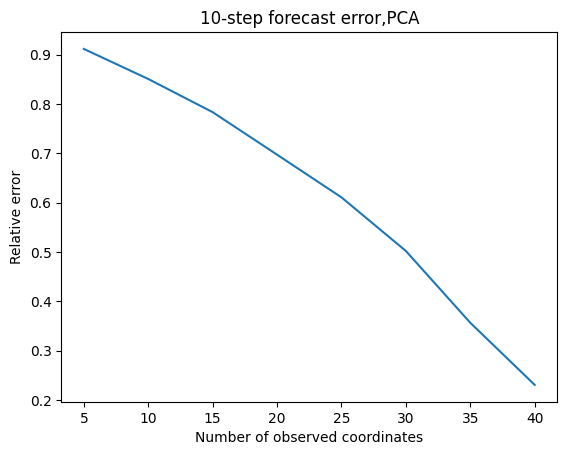

In [ ]:
plt.plot(5*torch.arange(1,9),ten_step_full_pca)
plt.title('10-step forecast error,PCA')
plt.xlabel('Number of observed coordinates')
plt.ylabel('Relative error')

Text(0, 0.5, 'Relative error')

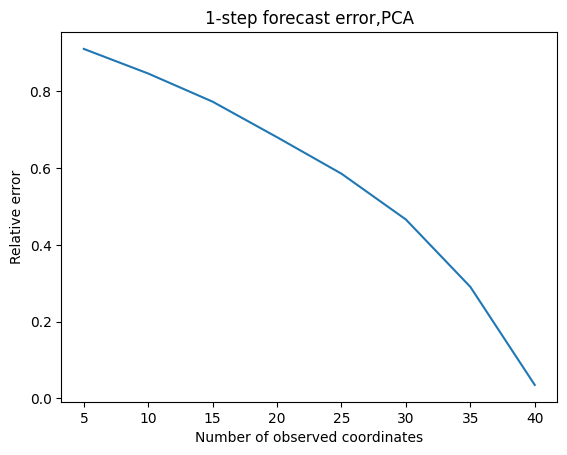

In [48]:
plt.plot(5*torch.arange(1,9),one_step_full_pca)
plt.title('1-step forecast error,PCA')
plt.xlabel('Number of observed coordinates')
plt.ylabel('Relative error')

In [33]:
# ============================================================
# FOURIER SNAPSHOT ENCODER / DECODER
# ============================================================

def fourier_encode_snapshot(x_std, K):
    """
    x_std: (..., N)
    returns real Fourier coordinates (..., dF), dF = 1 + 2K
    using rFFT modes 0..K, with modes 1..K split into real/imag parts.
    Assumes K < N//2 to avoid Nyquist special case.
    """
    Xf = torch.fft.rfft(x_std, dim=-1)
    parts = [Xf[..., 0].real.unsqueeze(-1)]
    for k in range(1, K + 1):
        parts.append(Xf[..., k].real.unsqueeze(-1))
        parts.append(Xf[..., k].imag.unsqueeze(-1))
    return torch.cat(parts, dim=-1)


def fourier_decode_snapshot(s, N, K):
    """
    s: (..., dF), dF = 1 + 2K
    returns x_std_hat: (..., N)
    """
    shape_prefix = s.shape[:-1]
    ctype = torch.complex128 if s.dtype == torch.float64 else torch.complex64
    Xf = torch.zeros(*shape_prefix, N // 2 + 1, device=s.device, dtype=ctype)

    Xf[..., 0] = s[..., 0].to(Xf.real.dtype)

    idx = 1
    for k in range(1, K + 1):
        re = s[..., idx]
        im = s[..., idx + 1]
        Xf[..., k] = torch.complex(re, im)
        idx += 2

    return torch.fft.irfft(Xf, n=N, dim=-1)


# ============================================================
# WINDOW BUILDERS
# ============================================================

def build_fourier_window_sequence(traj_std, L, K):
    """
    Full-state Fourier windows from standardized full trajectories.

    traj_std: (T, B, N)
    returns:
        S_seq: (B, n_t, L*dF), newest->oldest
        t_vals: list of window-end times
    """
    T, B, N = traj_std.shape
    F_seq = fourier_encode_snapshot(traj_std, K=K)                  # (T, B, dF)
    dF = F_seq.shape[-1]

    t0 = L - 1
    t1 = T - 1
    t_vals = list(range(t0, t1 + 1))
    n_t = len(t_vals)

    S_seq = torch.empty(B, n_t, L * dF, device=traj_std.device, dtype=traj_std.dtype)

    for j in range(B):
        for i, t in enumerate(t_vals):
            block = F_seq[t-L+1:t+1, j, :]                          # oldest->newest
            block = torch.flip(block, dims=[0])                     # newest->oldest
            S_seq[j, i, :] = block.reshape(-1)

    return S_seq, t_vals


def build_partial_windows_from_indices(traj_std, obs_idx, L, T_end=None):
    """
    Partial observed windows from standardized trajectories.

    traj_std: (T, B, N)
    obs_idx: list/1D tensor of observed indices
    returns:
        U_seq: (B, n_t, L*p), newest->oldest
        t_vals
    """
    if T_end is None:
        T_end = traj_std.shape[0]

    x = traj_std[:T_end]
    x_obs = x[:, :, obs_idx]                                         # (T_end, B, p)

    T_use, B, p = x_obs.shape
    t0 = L - 1
    t1 = T_use - 1
    t_vals = list(range(t0, t1 + 1))
    n_t = len(t_vals)

    U_seq = torch.empty(B, n_t, L * p, device=traj_std.device, dtype=traj_std.dtype)

    for j in range(B):
        for i, t in enumerate(t_vals):
            window = x_obs[t-L+1:t+1, j, :]                          # oldest->newest
            window = torch.flip(window, dims=[0])                    # newest->oldest
            U_seq[j, i, :] = window.reshape(-1)

    return U_seq, t_vals


# ============================================================
# LATENT ROLLOUT
# ============================================================

def rollout_latent(S0_std, Omega, b, sigma, P, W, steps):
    """
    S0_std: (B, d)
    W predicts one-step increment in standardized latent coordinates
    """
    future = torch.empty(steps + 1, *S0_std.shape, device=S0_std.device, dtype=S0_std.dtype)
    future[0] = S0_std
    s = S0_std
    for h in range(steps):
        ds = phi_batch(s, Omega, b, sigma, P) @ W
        s = s + ds
        future[h + 1] = s
    return future


# ============================================================
# DECODING FOURIER WINDOWS
# ============================================================

def decode_fourier_window_rollout_std(S_future_std, S_mean, S_std, N, L, K, mu_x, sd_x):
    """
    S_future_std: (steps+1, B, d_window)
    S_mean, S_std: (1, d_window)
    mu_x, sd_x: (1,1,N)

    returns:
        X_hat:      (steps+1, B, N) full-state forecasts in original scale
        X_hat_std:  (steps+1, B, N) full-state forecasts in standardized scale
        W_hat_std:  (steps+1, B, L, dF) decoded Fourier windows
        Xw_hat_std: (steps+1, B, L, N) decoded physical windows
    """
    dF = 1 + 2 * K

    # undo latent normalization
    S_future = S_mean + S_std * S_future_std                         # (steps+1, B, L*dF)

    # reshape to Fourier window
    W_hat_std = S_future.reshape(S_future.shape[0], S_future.shape[1], L, dF)

    # decode every Fourier snapshot
    Xw_hat_std = fourier_decode_snapshot(W_hat_std, N=N, K=K)        # (steps+1, B, L, N)

    # newest snapshot is index 0 because windows are newest->oldest
    X_hat_std = Xw_hat_std[:, :, 0, :]
    X_hat = mu_x + sd_x * X_hat_std

    return X_hat, X_hat_std, W_hat_std, Xw_hat_std


# ============================================================
# ERROR HELPERS
# ============================================================

def compute_rel_errors_fullstate(X_hat_std, traj, mu_x, sd_x, T_train, steps):
    """
    X_hat_std[0] corresponds to time T_train-1
    X_hat_std[h] compared to truth at time T_train + h - 1
    """
    traj_future = traj[T_train:T_train + steps]                      # (steps, B, N)
    traj_future_std = (traj_future - mu_x) / sd_x

    errs = []
    for h in range(1, steps + 1):
        err = (
            torch.linalg.norm(X_hat_std[h] - traj_future_std[h - 1]) /
            torch.linalg.norm(traj_future_std[h - 1])
        ).item()
        errs.append(err)
    return errs


def compute_rel_errors_observed(X_hat_std, traj, mu_x, sd_x, T_train, steps, obs_idx):
    """
    Error only on observed coordinates.
    """
    traj_future = traj[T_train:T_train + steps]
    traj_future_std = (traj_future - mu_x) / sd_x

    errs = []
    for h in range(1, steps + 1):
        pred = X_hat_std[h, :, obs_idx]
        true = traj_future_std[h - 1, :, obs_idx]
        err = (torch.linalg.norm(pred - true) / torch.linalg.norm(true)).item()
        errs.append(err)
    return errs


# ============================================================
# MAIN EXPERIMENT: FOURIER WINDOW + PARTIAL ROLLOUT
# ============================================================

def run_fourier_window_partial_rollout(
    traj,
    obs_idx,
    T_train,
    steps,
    L,
    K_fourier=19,
    P_A=512,
    P_D=512,
    sigma_A=1.0,
    sigma_D=1.0,
    lam_A=1e-2,
    lam_D=1e-2,
):
    """
    Full states in training, partial observations at rollout.

    Latent state:
        s_t = truncated-Fourier-window code of (x_t, ..., x_{t-L+1})

    Learns:
      1) inference map A: partial observed window -> Fourier-window latent state
      2) latent dynamics Delta: s_t -> s_{t+1} - s_t

    Rollout:
      - infer initial latent state from last partial training window
      - roll forward in latent space
      - decode to full window
      - extract newest state forecast

    Returns dict with full-state and observed-coordinate errors.
    """
    T, B, N = traj.shape
    device = traj.device
    dtype = traj.dtype

    # --------------------------------------------------------
    # 1) standardize full training states
    # --------------------------------------------------------
    traj_train, mu_x, sd_x, traj_train_std = standardize_train_block(traj, T_train)

    # --------------------------------------------------------
    # 2) build FULL Fourier-window latent sequence from training states
    # --------------------------------------------------------
    S_seq, t_vals_full = build_fourier_window_sequence(traj_train_std, L=L, K=K_fourier)
    # S_seq: (B, n_t, d_window)

    B_, n_t, d_window = S_seq.shape
    assert B_ == B
    assert t_vals_full[-1] == T_train - 1

    # --------------------------------------------------------
    # 3) fit latent one-step dynamics on full Fourier-window states
    # --------------------------------------------------------
    S_train = S_seq[:, :-1, :].reshape(-1, d_window)
    dS = (S_seq[:, 1:, :] - S_seq[:, :-1, :]).reshape(-1, d_window)

    S_mean = S_train.mean(dim=0, keepdim=True)
    S_std = S_train.std(dim=0, keepdim=True) + 1e-6

    S_seq_std = (S_seq - S_mean) / S_std
    S_train_std = S_seq_std[:, :-1, :].reshape(-1, d_window)
    dS_std = (S_seq_std[:, 1:, :] - S_seq_std[:, :-1, :]).reshape(-1, d_window)

    ell_D = median_ell(S_train_std)
    Omega_D = torch.randn(P_D, d_window, device=device, dtype=dtype) / ell_D
    b_D = 2 * torch.pi * torch.rand((P_D,), device=device, dtype=dtype)

    W_D = solve_W(S_train_std, dS_std, Omega_D, b_D, sigma=sigma_D, P=P_D, lam=lam_D)

    # --------------------------------------------------------
    # 4) build PARTIAL observed windows and fit inference map
    # --------------------------------------------------------
    U_obs_seq, t_vals_obs = build_partial_windows_from_indices(
        traj_train_std, obs_idx=obs_idx, L=L, T_end=T_train
    )
    # U_obs_seq: (B, n_t, L*p)

    assert t_vals_obs == t_vals_full

    U_train = U_obs_seq.reshape(-1, U_obs_seq.shape[-1])             # (B*n_t, L*p)
    S_target_train = S_seq_std.reshape(-1, d_window)                 # (B*n_t, d_window)

    ell_A = median_ell(U_train)
    Omega_A = torch.randn(P_A, U_train.shape[1], device=device, dtype=dtype) / ell_A
    b_A = 2 * torch.pi * torch.rand((P_A,), device=device, dtype=dtype)

    W_A = solve_W(U_train, S_target_train, Omega_A, b_A, sigma=sigma_A, P=P_A, lam=lam_A)

    # --------------------------------------------------------
    # 5) infer initial latent state from last partial training window
    # --------------------------------------------------------
    U0 = U_obs_seq[:, -1, :]                                         # (B, L*p), window ending at T_train-1
    S0_std = phi_batch(U0, Omega_A, b_A, sigma_A, P_A) @ W_A        # (B, d_window)

    # --------------------------------------------------------
    # 6) latent rollout
    # --------------------------------------------------------
    S_future_std = rollout_latent(S0_std, Omega_D, b_D, sigma_D, P_D, W_D, steps)

    # --------------------------------------------------------
    # 7) decode to full windows and extract newest state
    # --------------------------------------------------------
    X_hat, X_hat_std, W_hat_std, Xw_hat_std = decode_fourier_window_rollout_std(
        S_future_std, S_mean, S_std, N, L, K_fourier, mu_x, sd_x
    )

    # --------------------------------------------------------
    # 8) errors
    # --------------------------------------------------------
    errs_full = compute_rel_errors_fullstate(X_hat_std, traj, mu_x, sd_x, T_train, steps)
    errs_obs = compute_rel_errors_observed(X_hat_std, traj, mu_x, sd_x, T_train, steps, obs_idx)

    return {
        "errs_full": errs_full,
        "errs_obs": errs_obs,
        "X_hat": X_hat,
        "X_hat_std": X_hat_std,
        "W_hat_std": W_hat_std,
        "Xw_hat_std": Xw_hat_std,
        "S_future_std": S_future_std,
        "S_seq_std": S_seq_std,
        "mu_x": mu_x,
        "sd_x": sd_x,
        "S_mean": S_mean,
        "S_std": S_std,
        "Omega_A": Omega_A,
        "b_A": b_A,
        "W_A": W_A,
        "Omega_D": Omega_D,
        "b_D": b_D,
        "W_D": W_D,
        "t_vals": t_vals_full,
    }

In [59]:
T, B, N = traj.shape
T_train = T // 2
steps = 10
L = 40

one_step_full_fourier = torch.zeros(8)
one_step_obs_fourier = torch.zeros(8)
ten_step_full_fourier = torch.zeros(8)
ten_step_obs_fourier = torch.zeros(8)

for i in range(1,9):

# Example: leave out coordinate 0
    obs_idx = torch.arange(1, 5*i, device=traj.device)

    out_fourier_partial = run_fourier_window_partial_rollout(
        traj=traj,
        obs_idx=obs_idx,
        T_train=T_train,
        steps=steps,
        L=L,
        K_fourier=19,
        P_A=512,
        P_D=512,
        sigma_A=1.0,
        sigma_D=1.0,
        lam_A=1e-2,
        lam_D=1e-2,
    )
    one_step_full_fourier[i-1] = out_fourier_partial["errs_full"][0]
    one_step_obs_fourier[i-1] = out_fourier_partial["errs_obs"][0]
    ten_step_full_fourier[i-1] = out_fourier_partial["errs_full"][-1]
    ten_step_obs_fourier[i-1] = out_fourier_partial["errs_obs"][-1]

    print("Full-state rollout errors:", out_fourier_partial["errs_full"])
    print("Observed-coordinate rollout errors:", out_fourier_partial["errs_obs"])

Full-state rollout errors: [0.9220545887947083, 0.9217782616615295, 0.9215726852416992, 0.9214528203010559, 0.9214343428611755, 0.9215295910835266, 0.921750009059906, 0.9221023917198181, 0.9225930571556091, 0.9232231974601746]
Observed-coordinate rollout errors: [0.05217960849404335, 0.06670252978801727, 0.0841568112373352, 0.10407394170761108, 0.12610505521297455, 0.1499566286802292, 0.1753567010164261, 0.2020406872034073, 0.22974823415279388, 0.2582252025604248]
Full-state rollout errors: [0.8609786033630371, 0.8608602285385132, 0.8608531355857849, 0.860984206199646, 0.8612831234931946, 0.8617767095565796, 0.8624902367591858, 0.8634440898895264, 0.8646547794342041, 0.8661322593688965]
Observed-coordinate rollout errors: [0.06156836077570915, 0.07420523464679718, 0.08995446562767029, 0.10828959196805954, 0.12879818677902222, 0.15115481615066528, 0.1750853806734085, 0.20034167170524597, 0.22668592631816864, 0.2538841962814331]
Full-state rollout errors: [0.7911962270736694, 0.791335344

Text(0, 0.5, 'Relative error')

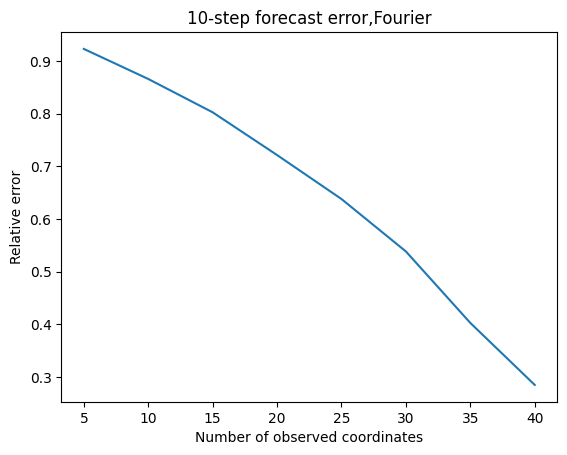

In [60]:
plt.plot(5*torch.arange(1,9),ten_step_full_fourier)
plt.title('10-step forecast error,Fourier')
plt.xlabel('Number of observed coordinates')
plt.ylabel('Relative error')

In [56]:
ten_step_full_fourier

tensor([0.9472, 0.9121, 0.8745, 0.8261, 0.7814, 0.7310, 0.6684, 0.6313])

Text(0, 0.5, 'Relative error')

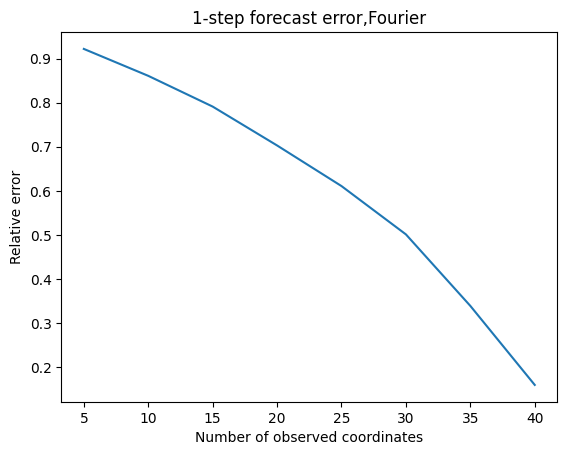

In [61]:
plt.plot(5*torch.arange(1,9),one_step_full_fourier)
plt.title('1-step forecast error,Fourier')
plt.xlabel('Number of observed coordinates')
plt.ylabel('Relative error')